# 10 · Build the project: one row per building
**Know Before You Rent · Team BUTA**

This notebook turns the cleaned datasets into the table the model learns from. **One row = one residential building with 3+ apartments.**

| Feature group | Examples | Answers |
|---|---|---|
| Building traits | age, era, apartments, floors, elevator vs walk-up | Q3 |
| Own history (previous 6 months) | complaints per problem type, violations by class (A/B/C), bedbugs, evictions | Q1 |
| Landlord record | the landlord's **other** buildings' complaint rate per type (leave-one-out) | Q2 |
| 100 m around it | complaints per type in other buildings within 100 m | Q4 |
| **Targets** | `y_<type>` = 1 if the building gets that complaint type **next four months** | Q5 |

**Time split, with historical-snapshot limitations documented in README:**
- **Train:** history January–June 2025 → predict July–October 2025.
- **Test:** history January–June 2026 → predict July–October 2026.

Code: `src/features_housing.py`.

**Study window: January 1, 2025–October 31, 2026.** Annual comparisons should use January–October in both years. Housing prediction uses six-month histories and four-month outcomes; older figures and reports describe the previous study.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src import features_housing as F
from src.plots import save, ACCENT, MUTED

pd.set_option("display.float_format", "{:,.3f}".format)
inp = F.load_inputs()
universe = F.building_universe(inp["pluto"], inp["landlords"])
print(f"Buildings (3+ apartments): {len(universe):,} | apartments: {universe.unitsres.sum():,.0f} | "
      f"registered with HPD: {universe.is_registered.mean():.1%}")

Buildings (3+ apartments): 172,468 | apartments: 2,867,092 | registered with HPD: 80.8%


## 1. The 100 m neighborhood graph

In [2]:
A = F.neighbor_matrix(universe)
deg = np.asarray(A.sum(axis=1)).ravel()
print(f"Building pairs within {F.NEIGHBOR_RADIUS_M} m: {A.nnz // 2:,} | median neighbors per building: {np.median(deg):.0f}")

Building pairs within 100 m: 2,771,981 | median neighbors per building: 30


## 2. Build the train (2025) and test (2026) tables

In [3]:
import json
REBUILD = False
stamp = F.config.PROCESSED_DIR / "study.json"
current_cache = stamp.exists() and json.loads(stamp.read_text()).get("study_id") == F.config.STUDY_ID
if REBUILD or not current_cache or not all((F.config.PROCESSED_DIR / f"building_features_{w}.parquet").exists() for w in ("train", "test")):
    F.build_tables()
train = pd.read_parquet(str(F.FEATURES_FILE).format(window="train"))
test = pd.read_parquet(str(F.FEATURES_FILE).format(window="test"))
assert train.bbl.tolist() == universe.bbl.tolist()
assert test.bbl.tolist() == universe.bbl.tolist()
print("train", train.shape, "| test", test.shape, "| features:", len(F.feature_columns(train)))
train.head(3).T.head(45)


train (172468, 80) | test (172468, 80) | features: 56


,0,1,2
bbl,1000050010,1000070038,1000077501
borough,MANHATTAN,MANHATTAN,MANHATTAN
zipcode,10004,10004,10004
latitude,40.703,40.703,40.703
longitude,-74.011,-74.011,-74.011
yearbuilt,"1,969.000","1,830.000","1,880.000"
building_age,56.000,195.000,145.000
era,1960-79,<1920,<1920
unitsres,"1,320.000",3.000,42.000
numfloors,32.000,5.000,6.000


In [4]:
# How common is each problem next four months? (the base rate the model must beat)
pd.DataFrame({"Jul–Oct 2025": train[F.target_columns()].mean(), "Jul–Oct 2026": test[F.target_columns()].mean()}).mul(100).round(1) \
    .rename(index=lambda s: s[2:]).rename_axis("% of buildings with ≥1 complaint")

,Jul–Oct 2025,Jul–Oct 2026
% of buildings with ≥1 complaint,,
heat_hot_water,6.000,5.700
pests,5.000,5.800
leaks_mold,5.600,6.800
plumbing,4.600,5.500
paint_plaster,4.500,5.200
doors_windows,3.900,4.400
safety,1.500,1.800


## 3. First answers, before any model
Each table shows the share of buildings that got that problem in **July–October 2025**, split by one factor measured in **January–June 2025**.

### Q1: does a building's history predict its future?

In [5]:
rows = []
for t in F.TARGET_TYPES:
    s = F.slug(t)
    had = train[f"c_{s}"] > 0
    rows.append({"problem": t, "had it in January–June 2025": train.loc[had, f"y_{s}"].mean(),
                 "didn't": train.loc[~had, f"y_{s}"].mean()})
q1 = pd.DataFrame(rows).set_index("problem")
q1["× more likely"] = q1.iloc[:, 0] / q1.iloc[:, 1]
q1

,had it in January–June 2025,didn't,× more likely
problem,,,
heat/hot water,0.342,0.021,15.926
pests,0.426,0.029,14.911
leaks/mold,0.436,0.029,14.841
plumbing,0.383,0.024,16.005
paint/plaster,0.424,0.023,18.423
doors/windows,0.368,0.021,17.551
safety,0.182,0.012,15.479


### Q2: does the landlord matter?
Buildings with a multi-building landlord, split by how their landlord's **other** buildings did (quartiles of the leave-one-out rate).

In [6]:
port = train[train.has_portfolio]
rows = {}
for t in F.TARGET_TYPES:
    s = F.slug(t)
    q = pd.qcut(port[f"ll_rate_{s}"].rank(method="first"), 4, labels=["best 25%", "Q2", "Q3", "worst 25%"])
    rows[t] = port.groupby(q, observed=True)[f"y_{s}"].mean()
q2 = pd.DataFrame(rows).T
q2["worst ÷ best"] = q2["worst 25%"] / q2["best 25%"]
print(f"Buildings with a multi-building landlord: {len(port):,} ({len(port) / len(train):.0%})")
q2

Buildings with a multi-building landlord: 57,102 (33%)


,best 25%,Q2,Q3,worst 25%,worst ÷ best
heat/hot water,0.042,0.061,0.151,0.265,6.363
pests,0.046,0.036,0.118,0.225,4.871
leaks/mold,0.044,0.041,0.134,0.275,6.304
plumbing,0.035,0.037,0.104,0.233,6.732
paint/plaster,0.036,0.026,0.098,0.237,6.626
doors/windows,0.035,0.026,0.085,0.190,5.358
safety,0.020,0.013,0.028,0.067,3.257


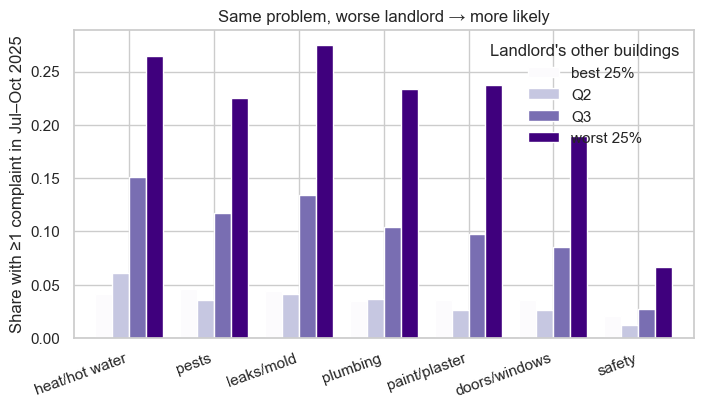

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
q2.drop(columns="worst ÷ best").plot(kind="bar", ax=ax, colormap="Purples", width=0.8)
ax.set(ylabel="Share with ≥1 complaint in Jul–Oct 2025", xlabel="", title="Same problem, worse landlord → more likely")
ax.legend(title="Landlord's other buildings", frameon=False)
plt.xticks(rotation=20, ha="right")
save(fig, "rent09a_landlord_effect")

### Q3: building age and type

In [8]:
train.groupby("era")[F.target_columns()].mean().rename(columns=lambda s: s[2:]).loc[
    ["<1920", "1920-39", "1940-59", "1960-79", "1980-99", "2000+"]].mul(100).round(1)

,heat_hot_water,pests,leaks_mold,plumbing,paint_plaster,doors_windows,safety
era,,,,,,,
<1920,5.300,4.300,4.900,3.900,3.700,3.300,1.300
1920-39,7.400,6.000,6.800,5.800,5.900,4.900,1.900
1940-59,8.700,6.400,6.700,5.700,5.900,4.700,2.000
1960-79,4.700,3.900,4.000,3.400,3.300,2.600,1.000
1980-99,2.700,2.900,3.200,2.500,2.400,2.000,0.900
2000+,4.300,4.500,5.200,4.100,3.500,3.600,1.400


In [9]:
kind = np.select([train.is_elevator, train.is_walkup], ["elevator", "walk-up"], "other")
train.groupby(kind)[F.target_columns()].mean().rename(columns=lambda s: s[2:]).mul(100).round(1)

,heat_hot_water,pests,leaks_mold,plumbing,paint_plaster,doors_windows,safety
elevator,24.200,19.400,21.600,18.400,18.000,15.000,5.500
other,3.500,2.700,2.900,2.600,2.100,2.100,1.000
walk-up,4.300,3.700,4.200,3.400,3.300,2.900,1.200


### Q4: does the 100 m neighborhood add information?
Only buildings **without** that problem in their own history, so the neighborhood is the only signal.

In [10]:
rows = {}
for t in F.TARGET_TYPES:
    s = F.slug(t)
    clean_hist = train[train[f"c_{s}"] == 0]
    nb = pd.qcut(clean_hist[f"nb100_{s}"].rank(method="first"), 4, labels=["quietest 25%", "Q2", "Q3", "busiest 25%"])
    rows[t] = clean_hist.groupby(nb, observed=True)[f"y_{s}"].mean()
q4 = pd.DataFrame(rows).T
q4["busiest ÷ quietest"] = q4["busiest 25%"] / q4["quietest 25%"]
q4

,quietest 25%,Q2,Q3,busiest 25%,busiest ÷ quietest
heat/hot water,0.009,0.013,0.022,0.042,4.557
pests,0.017,0.014,0.027,0.056,3.317
leaks/mold,0.016,0.016,0.027,0.058,3.596
plumbing,0.013,0.012,0.022,0.048,3.674
paint/plaster,0.013,0.010,0.022,0.047,3.590
doors/windows,0.012,0.008,0.021,0.043,3.571
safety,0.011,0.006,0.009,0.020,1.864


## 4. What we have
- Train and test tables are saved to `data/processed/building_features_train.parquet` and `building_features_test.parquet`.
- The tables above give **descriptive** answers to Q1–Q4.

The next notebook trains a model per problem type (Q5). It measures how much each feature group adds, and is tested on July–October 2026, a year the model never saw.